# CALOR Y MAYORES EN MADRID

## Índice de riesgo por calor de los centros de mayores

**Marco (IPCC):** Riesgo = Peligro × Exposición × Vulnerabilidad × (1 − Capacidad).
- **Peligro:** temperatura de superficie de la isócrona normal.
- **Exposición:** plazas del centro, comparadas dentro de su tipo.
- **Vulnerabilidad:** tipo de centro (grado de dependencia) y antigüedad del edificio.
- **Capacidad:** distancia andando al agua, a los refugios y a la salud, y sombra y confort de la isócrona.

**Decisión:** la fórmula del traspaso divide entre la capacidad (Riesgo = Peligro × Exposición × Vulnerabilidad / Capacidad). Se sustituye por una multiplicación por (1 − Capacidad), porque el centro con menos recursos tendría capacidad 0 y la división daría un riesgo infinito. Con (1 − Capacidad) se mantiene la misma idea: cuanta más capacidad, menos riesgo. Un centro sin ningún recurso conserva todo su riesgo (se multiplica por 1) y uno con la máxima capacidad lo reduce a 0.

## 1. Capas de servicios y - importamos las librerías

In [1]:
import sys
import glob
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import osmnx as ox
import networkx as nx
from scipy.stats import spearmanr

sys.path.append("../scrips")
from config import RUTA_RAW, RUTA_CLEAN, CRS_PROYECTO

- localizamos los CSV de cada carpeta

In [2]:
for carpeta in ["fuentes", "centrosalud", "mercados"]:
    print(carpeta, glob.glob(RUTA_RAW + carpeta + "/*.csv"))

fuentes ['../raw/fuentes\\300051-26-fuentes.csv']
centrosalud ['../raw/centrosalud\\212769-0-atencion-medica.csv']
mercados ['../raw/mercados\\200967-4-mercados-csv.csv']


- cargamos las fuentes y revisamos columnas, estado y uso

In [3]:
fuentes = pd.read_csv(glob.glob(RUTA_RAW + "fuentes/*.csv")[0], sep=";", encoding="utf-8")
print(fuentes.shape)
print(fuentes.columns.tolist())
print(fuentes["ESTADO"].value_counts(dropna=False))
print(fuentes["USO"].value_counts(dropna=False))

(2314, 24)
['ID', 'DESC_CLASIFICACION', 'COD_BARRIO', 'BARRIO', 'COD_DISTRITO', 'DISTRITO', 'ESTADO', 'COORD_GIS_X', 'COORD_GIS_Y', 'SISTEMA_COORD', 'LATITUD', 'LONGITUD', 'TIPO_VIA', 'NOM_VIA', 'NUM_VIA', 'COD_POSTAL', 'DIRECCION_AUX', 'NDP', 'FECHA_INSTALACION', 'CODIGO_INTERNO', 'CONTRATO_COD', 'UBICACION', 'USO', 'MODELO']
ESTADO
OPERATIVO               2208
FUERA_DE_SERVICIO        103
CERRADA_TEMPORALMENT       3
Name: count, dtype: int64
USO
PERSONAS               2134
PERSONAS_Y_MASCOTAS     156
MASCOTAS                 15
NaN                       9
Name: count, dtype: int64


- cargamos los centros de atención médica y revisamos sus columnas

In [4]:
salud = pd.read_csv(glob.glob(RUTA_RAW + "centrosalud/*.csv")[0], sep=";", encoding="latin-1")
print(salud.shape)
print(salud.columns.tolist())

(278, 32)
['PK', 'NOMBRE', 'DESCRIPCION-ENTIDAD', 'HORARIO', 'EQUIPAMIENTO', 'TRANSPORTE', 'DESCRIPCION', 'ACCESIBILIDAD', 'CONTENT-URL', 'NOMBRE-VIA', 'CLASE-VIAL', 'TIPO-NUM', 'NUM', 'PLANTA', 'PUERTA', 'ESCALERAS', 'ORIENTACION', 'LOCALIDAD', 'PROVINCIA', 'CODIGO-POSTAL', 'COD-BARRIO', 'BARRIO', 'COD-DISTRITO', 'DISTRITO', 'COORDENADA-X', 'COORDENADA-Y', 'LATITUD', 'LONGITUD', 'TELEFONO', 'FAX', 'EMAIL', 'TIPO']


- cargamos los mercados y revisamos sus columnas

In [5]:
mercados = pd.read_csv(glob.glob(RUTA_RAW + "mercados/*.csv")[0], sep=";", encoding="latin-1")
print(mercados.shape)
print(mercados.columns.tolist())

(45, 32)
['PK', 'NOMBRE', 'DESCRIPCION-ENTIDAD', 'HORARIO', 'EQUIPAMIENTO', 'TRANSPORTE', 'DESCRIPCION', 'ACCESIBILIDAD', 'CONTENT-URL', 'NOMBRE-VIA', 'CLASE-VIAL', 'TIPO-NUM', 'NUM', 'PLANTA', 'PUERTA', 'ESCALERAS', 'ORIENTACION', 'LOCALIDAD', 'PROVINCIA', 'CODIGO-POSTAL', 'COD-BARRIO', 'BARRIO', 'COD-DISTRITO', 'DISTRITO', 'COORDENADA-X', 'COORDENADA-Y', 'LATITUD', 'LONGITUD', 'TELEFONO', 'FAX', 'EMAIL', 'TIPO']


**Decisión:** se usan las fuentes OPERATIVAS para personas (PERSONAS y PERSONAS_Y_MASCOTAS). Se excluyen las fuera de servicio o cerradas temporalmente, las que son solo para mascotas y las 9 sin uso indicado.

- filtramos las fuentes y las convertimos en capa de puntos

In [6]:
fuentes = fuentes[
    (fuentes["ESTADO"] == "OPERATIVO") &
    (fuentes["USO"].isin(["PERSONAS", "PERSONAS_Y_MASCOTAS"]))
]
fuentes = gpd.GeoDataFrame(
    fuentes[["ID", "UBICACION"]].copy(),
    geometry=gpd.points_from_xy(fuentes["COORD_GIS_X"], fuentes["COORD_GIS_Y"]),
    crs=CRS_PROYECTO
)
fuentes["nombre_servicio"] = "Fuente de agua"
fuentes["direccion"] = fuentes["UBICACION"]
print(fuentes.shape)

(2186, 5)


- función que une el tipo de vía, el nombre de la vía y el número en una dirección

In [7]:
def crear_direccion(tabla):
    """Une el tipo de vía, el nombre de la vía y el número en una dirección legible."""
    clase = tabla["CLASE-VIAL"].fillna("").astype(str).str.capitalize()
    via = tabla["NOMBRE-VIA"].fillna("").astype(str).str.title()
    numero = tabla["NUM"].fillna("").astype(str).str.replace(".0", "", regex=False)
    return (clase + " " + via + ", " + numero).str.strip(" ,")

- revisamos las coordenadas de los mercados y los convertimos en capa de puntos

In [8]:
print("Mercados sin coordenadas:", mercados["COORDENADA-X"].isnull().sum())
mercados = mercados.dropna(subset=["COORDENADA-X", "COORDENADA-Y"]).copy()
mercados["direccion"] = crear_direccion(mercados)
mercados = gpd.GeoDataFrame(
    mercados[["PK", "NOMBRE", "direccion"]].copy(),
    geometry=gpd.points_from_xy(mercados["COORDENADA-X"], mercados["COORDENADA-Y"]),
    crs=CRS_PROYECTO
)
print(mercados.shape)
print("Mercados sin coordenadas tras el filtro:", mercados.geometry.is_empty.sum())
mercados[["NOMBRE", "direccion"]].head()

Mercados sin coordenadas: 1
(44, 4)
Mercados sin coordenadas tras el filtro: 0


,NOMBRE,direccion
0,Mercado municipal de Alto de Extremadura,"Paseo Jesuitas, 44"
1,Mercado municipal de Antón Martín,"Calle Santa Isabel, 5"
2,Mercado municipal de Argüelles,"Calle Altamirano, 7"
3,Mercado municipal de Bami,"Plaza Bami, 32"
4,Mercado municipal de Barceló,"Calle Barcelo, 6"


- revisamos los tipos de centros de atención médica

In [9]:
salud["TIPO"].value_counts(dropna=False)

TIPO
/contenido/entidadesYorganismos/CentrosAtencionMedica/CentrosSalud                          130
/contenido/entidadesYorganismos/CentrosAtencionMedica/HospitalesClinicasSanatorios           53
/contenido/entidadesYorganismos/CentrosAtencionMedica/CentrosPrevencionEnfermedades          27
/contenido/entidadesYorganismos/CentrosAtencionMedica/CentrosSaludMental                     26
/contenido/entidadesYorganismos/CentrosAtencionMedica/CentrosEspecialidadesMedicas           19
/contenido/entidadesYorganismos/CentrosAtencionMedica/CentrosAsistenciaDrogodependientes     18
/contenido/entidadesYorganismos/CentrosAtencionMedica/OtrosCentrosMedicos                     4
/contenido/entidadesYorganismos/CentrosAtencionSocial/CentrosRehabilitacionPsicosocial        1
Name: count, dtype: int64

**Decisión:** se usan los 130 centros de salud de atención primaria y los 53 hospitales, clínicas y sanatorios (urgencias por golpe de calor). Se descartan los centros de prevención, salud mental, especialidades, drogodependencias y otros, que no atienden urgencias. Se elimina el centro sin coordenadas.

- filtramos los centros de salud y hospitales y los convertimos en capa de puntos

In [10]:
tipos_salud = {
    "/contenido/entidadesYorganismos/CentrosAtencionMedica/CentrosSalud": "centro de salud",
    "/contenido/entidadesYorganismos/CentrosAtencionMedica/HospitalesClinicasSanatorios": "hospital"
}
salud = salud[salud["TIPO"].isin(tipos_salud.keys())].copy()
salud["tipo_salud"] = salud["TIPO"].map(tipos_salud)
salud = salud.dropna(subset=["COORDENADA-X", "COORDENADA-Y"])
salud["direccion"] = crear_direccion(salud)

salud = gpd.GeoDataFrame(
    salud[["PK", "NOMBRE", "tipo_salud", "direccion"]].copy(),
    geometry=gpd.points_from_xy(salud["COORDENADA-X"], salud["COORDENADA-Y"]),
    crs=CRS_PROYECTO
)
salud["nombre_servicio"] = salud["NOMBRE"]
print(salud.shape)
salud["tipo_salud"].value_counts()

(183, 6)


tipo_salud
centro de salud    130
hospital            53
Name: count, dtype: int64

**Decisión:** los refugios climáticos son los 44 mercados municipales y los 112 centros de mayores (hogares y clubes) del registro limpio, en línea con los refugios del verano de 2026.

- unimos mercados y centros de mayores en una sola capa de refugios

In [11]:
centros = gpd.read_file(RUTA_CLEAN + "centros_mayores.gpkg")
refugios_mayores = centros[centros["tipo_centro"] == "centro de mayores"][["codigo", "nombre", "geometry"]].copy()
refugios_mayores["tipo_refugio"] = "centro de mayores"
refugios_mayores["direccion"] = ""
refugios_mercados = mercados.rename(columns={"PK": "codigo", "NOMBRE": "nombre"})
refugios_mercados["tipo_refugio"] = "mercado"

refugios = pd.concat([refugios_mayores, refugios_mercados], ignore_index=True)
refugios["codigo"] = refugios["codigo"].astype(str)
refugios["nombre_servicio"] = refugios["nombre"]
print(refugios.shape)
refugios["tipo_refugio"].value_counts()

(156, 6)


tipo_refugio
centro de mayores    112
mercado               44
Name: count, dtype: int64

**Nota:** los centros de mayores tienen dos papeles: son centros del estudio, con su isócrona y su índice, y son refugios para los demás centros. Al calcular la distancia al refugio más cercano, se excluye el propio centro.

## 2. Componentes del índice
- cargamos las isócronas, la relación centro-hexágono y los hexágonos

In [12]:
isocronas = gpd.read_file(RUTA_CLEAN + "isocronas_normales.gpkg")
centros_hexagonos = pd.read_csv(RUTA_CLEAN + "centros_hexagonos.csv")
hexagonos_todos = gpd.read_file(RUTA_CLEAN + "hexagonos_h3.gpkg")

indice = centros[["codigo", "nombre", "tipo_centro", "plazas", "titularidad", "geometry"]].copy()
indice = indice.merge(isocronas[["codigo", "pct_confort_1.5"]], on="codigo", how="left")
print(indice.shape)

(439, 7)


### 2.1 Peligro

- temperatura media medida y copa de árboles media de los hexágonos de la isócrona de cada centro

In [13]:
hexagonos_isocrona = centros_hexagonos.merge(hexagonos_todos[["h3", "lst", "pct_copa"]], on="h3", how="left")
resumen_isocrona = hexagonos_isocrona.groupby("codigo").agg(
    lst_isocrona=("lst", "mean"),
    copa_isocrona=("pct_copa", "mean")
).reset_index()

indice = indice.merge(resumen_isocrona, on="codigo", how="left")
indice[["lst_isocrona", "copa_isocrona"]].describe().round(2)

,lst_isocrona,copa_isocrona
count,439.00,439.00
mean,43.97,10.09
std,1.27,7.22
min,40.83,0.00
25%,43.11,5.23
50%,43.99,9.01
75%,44.74,13.06
max,48.16,43.05


**Observación:** el entorno de los centros está de media a 44,0 °C (de 40,8 a 48,2 °C) y tiene un 10,1 % de copa de árboles (de 0 a 43 %)

### 2.2 Exposición

**Decisión:** las plazas se comparan dentro de cada tipo de centro (percentil de 0 a 1), porque las plazas de los centros de mayores son socios o aforo y no son comparables con las de residencias y centros de día.

- percentil de las plazas dentro de cada tipo de centro

In [14]:
indice["exposicion"] = indice.groupby("tipo_centro")["plazas"].rank(pct=True)
indice.groupby("tipo_centro")["exposicion"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
tipo_centro,,,,,,,,
centro de día,154.0,0.50,0.29,0.01,0.28,0.44,0.76,1.0
centro de mayores,112.0,0.50,0.29,0.01,0.26,0.50,0.75,1.0
residencia,165.0,0.50,0.29,0.01,0.25,0.50,0.75,1.0
vivienda tutelada,8.0,0.56,0.31,0.12,0.34,0.56,0.78,1.0


**Observación:** al calcularse el percentil dentro de cada tipo, la exposición se reparte igual en todos los tipos (mediana de 0,5): cada centro se compara solo con los de su clase.

### 2.3 Vulnerabilidad

**Decisión:** la vulnerabilidad combina el tipo de centro y la antigüedad del edificio. El orden por tipo sigue el grado de dependencia de los usuarios: estar encamado, no salir de casa o no poder valerse por uno mismo son los principales factores de riesgo de muerte en olas de calor (metaanálisis de Bouchama y colaboradores, 2007, Archives of Internal Medicine). Los valores (residencia 1, centro de día 0,75, vivienda tutelada 0,5 y centro de mayores 0,25) son un supuesto que se comprueba en el bloque 3. La antigüedad del edificio se incluye a partir del estudio cualitativo de Pozo Menéndez y colaboradores (2024, apartado 3.2), basado en 24 entrevistas y 2 grupos focales con 45 participantes de tres centros de atención a la dependencia para personas con discapacidad en España. En ese estudio, los participantes señalaron los edificios antiguos y las instalaciones obsoletas, entre ellas la climatización, como una limitación de su confort térmico y su autonomía. En este proyecto se asume, por tanto, que un edificio más antiguo hace al centro más vulnerable al calor.

- valor de vulnerabilidad según el tipo de centro

In [15]:
escala_tipo = {"residencia": 1.0, "centro de día": 0.75, "vivienda tutelada": 0.5, "centro de mayores": 0.25}
indice["vulnerabilidad_tipo"] = indice["tipo_centro"].map(escala_tipo)
indice["vulnerabilidad_tipo"].value_counts()

vulnerabilidad_tipo
1.00    165
0.75    154
0.25    112
0.50      8
Name: count, dtype: int64

**Observación:** 165 residencias (1), 154 centros de día (0,75), 8 viviendas tuteladas (0,5) y 112 centros de mayores (0,25).

- año de construcción del edificio del Catastro en el que está cada centro

In [16]:
edificios = gpd.read_file(RUTA_RAW + "dato6/catastro_edificios.gpkg", columns=["beginning"])
edificios["anio"] = pd.to_numeric(edificios["beginning"].astype(str).str[:4], errors="coerce")

edificio_centro = gpd.sjoin_nearest(indice[["codigo", "geometry"]], edificios[["anio", "geometry"]],
                                    how="left", max_distance=50, distance_col="dist_edificio")
edificio_centro = edificio_centro.drop_duplicates(subset="codigo")
indice["anio_edificio"] = edificio_centro["anio"].values

print("Centros sin año de edificio:", indice["anio_edificio"].isnull().sum())
indice["anio_edificio"].describe()

Centros sin año de edificio: 1


count     438.000000
mean     1982.273973
std        29.619213
min      1860.000000
25%      1965.000000
50%      1991.500000
75%      2004.000000
max      2026.000000
Name: anio_edificio, dtype: float64

**Observación:** solo 1 centro no tiene edificio a menos de 50 m y se rellena con la mediana. La mediana es 1991: los edificios de los centros son relativamente recientes (muchas residencias se construyeron en los años 90 y 2000); el más antiguo es de 1860.

**Decisión:** los centros sin año de edificio se rellenan con la mediana de los demás centros. La antigüedad se pasa a percentil: 1 es el edificio más antiguo (el más vulnerable).

- percentil de antigüedad y vulnerabilidad final

In [17]:
indice["anio_edificio"] = indice["anio_edificio"].fillna(indice["anio_edificio"].median())
indice["vulnerabilidad_edificio"] = indice["anio_edificio"].rank(pct=True, ascending=False)
indice["vulnerabilidad"] = (indice["vulnerabilidad_tipo"] + indice["vulnerabilidad_edificio"]) / 2
indice[["vulnerabilidad_tipo", "vulnerabilidad_edificio", "vulnerabilidad"]].describe().round(2)

,vulnerabilidad_tipo,vulnerabilidad_edificio,vulnerabilidad
count,439.00,439.00,439.00
mean,0.71,0.50,0.61
std,0.30,0.29,0.20
min,0.25,0.01,0.14
25%,0.25,0.26,0.47
50%,0.75,0.50,0.60
75%,1.00,0.75,0.75
max,1.00,1.00,1.00


**Observación:** la vulnerabilidad media es de 0,61 (de 0,14 a 1); pesa más el tipo de centro, porque la mayoría son residencias y centros de día.

### 2.4 Capacidad: distancia andando a los servicios

**Decisión:** para el agua, los refugios y la salud se usa la distancia andando (por la red) desde el centro al servicio más cercano, porque ante un golpe de calor lo que importa es poder llegar a uno. Se busca hasta 1.000 m (unos 21 minutos a 0,8 m/s); en el bloque 3 se compara con el límite de la isócrona (720 m). Un centro de mayores no cuenta como refugio de sí mismo.

- cargamos la red y buscamos el cruce más cercano a cada centro y a cada servicio

In [18]:
LIMITE_SERVICIOS = 1000
RADIO_SALIDA = 100

red = ox.load_graphml(RUTA_RAW + "osm/walk_graph_madrid.graphml")
red = ox.project_graph(red, to_crs=CRS_PROYECTO)
nodos = ox.graph_to_gdfs(red, edges=False)

indice["nodo"] = ox.distance.nearest_nodes(red, X=indice.geometry.x, Y=indice.geometry.y)
fuentes["nodo"] = ox.distance.nearest_nodes(red, X=fuentes.geometry.x, Y=fuentes.geometry.y)
salud["nodo"] = ox.distance.nearest_nodes(red, X=salud.geometry.x, Y=salud.geometry.y)
refugios["nodo"] = ox.distance.nearest_nodes(red, X=refugios.geometry.x, Y=refugios.geometry.y)

nodos_fuentes = set(fuentes["nodo"])
nodos_salud = set(salud["nodo"])
print("Cruces con fuente:", len(nodos_fuentes), "- con centro de salud u hospital:", len(nodos_salud))

Cruces con fuente: 2169 - con centro de salud u hospital: 178


**Observación:** las 2.186 fuentes se sitúan en 2.169 cruces y los 183 centros sanitarios en 178: casi cada servicio tiene su propio cruce.

**Decisión:** las distancias a los servicios se calculan desde el nodo puerta de cada centro, igual que las isócronas: un nodo virtual en la posición del centro, unido a los cruces a menos de 100 m por un tramo de su distancia real. Así cada centro sale a la red por su mejor salida, y no por un camino mal conectado.

- funciones para calcular las distancias por la red desde la puerta de cada centro

In [19]:
def nodos_de_salida(punto):
    """Devuelve los cruces a menos de RADIO_SALIDA m del centro; si no hay ninguno, el más cercano."""
    posiciones = nodos.sindex.query(punto.buffer(RADIO_SALIDA), predicate="intersects")
    if len(posiciones) == 0:
        return [ox.distance.nearest_nodes(red, X=punto.x, Y=punto.y)]
    return list(nodos.index[posiciones])


def distancias_desde_puerta(punto, limite):
    """Devuelve un diccionario con la distancia por la red desde la puerta del centro a cada cruce alcanzado."""
    salidas = nodos_de_salida(punto)
    red.add_node("puerta")
    for nodo in salidas:
        distancia = punto.distance(nodos.loc[nodo, "geometry"])
        red.add_edge("puerta", nodo, length=distancia)

    alcanzados = nx.single_source_dijkstra_path_length(red, "puerta", cutoff=limite, weight="length")
    red.remove_node("puerta")
    alcanzados.pop("puerta")
    return alcanzados

- distancia andando al agua, al refugio y a la salud más cercanos desde cada centro

In [20]:
def servicio_mas_cercano(servicios, alcanzados):
    """Devuelve la distancia andando, el nombre y la dirección del servicio más cercano entre los cruces alcanzados."""
    cercanos = servicios[servicios["nodo"].isin(list(alcanzados))].copy()
    if len(cercanos) == 0:
        return np.nan, None, None
    cercanos["distancia"] = cercanos["nodo"].map(alcanzados)
    mas_cercano = cercanos.sort_values("distancia").iloc[0]
    return mas_cercano["distancia"], mas_cercano["nombre_servicio"], mas_cercano["direccion"]


resultados = {"agua": [], "refugio": [], "salud": []}
for codigo, punto in zip(indice["codigo"], indice.geometry):
    alcanzados = distancias_desde_puerta(punto, LIMITE_SERVICIOS)
    otros_refugios = refugios[refugios["codigo"] != str(codigo)]
    for servicio, tabla in [("agua", fuentes), ("refugio", otros_refugios), ("salud", salud)]:
        resultados[servicio].append(servicio_mas_cercano(tabla, alcanzados))

for servicio in ["agua", "refugio", "salud"]:
    indice[f"dist_{servicio}"] = [distancia for distancia, _, _ in resultados[servicio]]
    indice[f"nombre_{servicio}"] = [nombre for _, nombre, _ in resultados[servicio]]
    indice[f"direccion_{servicio}"] = [direccion for _, _, direccion in resultados[servicio]]

indice[["dist_agua", "dist_refugio", "dist_salud"]].describe().round(1)

,dist_agua,dist_refugio,dist_salud
count,435.0,327.0,384.0
mean,217.5,472.8,430.6
std,154.1,279.6,238.1
min,19.1,3.6,16.3
25%,100.5,246.5,241.9
50%,186.2,476.8,424.9
75%,292.4,694.9,599.9
max,974.1,993.7,994.2


**Observación:**
1. 435 centros tienen una fuente a menos de 1 km andando (mediana de 186 m) y 384 un centro de salud u hospital (mediana de 425 m).
2. Solo 327 (el 74 %) tienen otro refugio a menos de 1 km, así que 112 centros no tienen ningún refugio a una distancia caminable.

## 3. Índice de riesgo

**Decisión:** las distancias se limitan al valor máximo de búsqueda: si no hay servicio, o está más lejos, se le asigna ese valor (el peor). Se calcula la capacidad con el límite de 1.000 m (central) y con el de la isócrona, 720 m, para comprobar la sensibilidad. Todos los indicadores se pasan a percentil de 0 a 1, donde 1 es la mejor situación (servicio más cerca, más sombra, más confort), y la capacidad es su media con el mismo peso.

- función que calcula la capacidad con un límite de distancia dado

In [21]:
def calcular_capacidad(tabla, limite):
    """Devuelve la capacidad de cada centro (0 a 1) con las distancias limitadas al valor dado."""
    indicadores = pd.DataFrame(index=tabla.index)
    for servicio in ["dist_agua", "dist_refugio", "dist_salud"]:
        distancia = tabla[servicio].fillna(limite).clip(upper=limite)
        indicadores[servicio] = distancia.rank(pct=True, ascending=False)
    indicadores["sombra"] = tabla["copa_isocrona"].rank(pct=True)
    indicadores["confort"] = tabla["pct_confort_1.5"].rank(pct=True)
    return indicadores.mean(axis=1)

- peligro, capacidad y riesgo con el límite central (1.000 m) y con el de la isócrona (720 m)

In [22]:
indice["peligro"] = indice["lst_isocrona"].rank(pct=True)
indice["capacidad"] = calcular_capacidad(indice, LIMITE_SERVICIOS)
indice["capacidad_720"] = calcular_capacidad(indice, 720)

indice["riesgo"] = indice["peligro"] * indice["exposicion"] * indice["vulnerabilidad"] * (1 - indice["capacidad"])
indice["riesgo_720"] = indice["peligro"] * indice["exposicion"] * indice["vulnerabilidad"] * (1 - indice["capacidad_720"])

indice[["peligro", "exposicion", "vulnerabilidad", "capacidad", "riesgo"]].describe().round(3)

,peligro,exposicion,vulnerabilidad,capacidad,riesgo
count,439.000,439.000,439.000,439.000,439.000
mean,0.501,0.505,0.606,0.501,0.086
std,0.289,0.289,0.200,0.149,0.096
min,0.003,0.006,0.139,0.052,0.000
25%,0.252,0.276,0.471,0.403,0.016
50%,0.501,0.491,0.598,0.508,0.056
75%,0.751,0.756,0.747,0.609,0.121
max,0.999,1.000,0.997,0.866,0.661


**Observación:** el riesgo tiene una mediana de 0,056 y un máximo de 0,661. Es muy asimétrico: pocos centros concentran el riesgo alto.

- comprobamos la sensibilidad: ¿cambia el orden de los centros con el límite de 720 m o con una escala de vulnerabilidad más sencilla (dependientes 1, autónomos 0,5)?

In [23]:
escala_simple = {"residencia": 1.0, "centro de día": 1.0, "vivienda tutelada": 0.5, "centro de mayores": 0.5}
vulnerabilidad_simple = (indice["tipo_centro"].map(escala_simple) + indice["vulnerabilidad_edificio"]) / 2
riesgo_escala_simple = indice["peligro"] * indice["exposicion"] * vulnerabilidad_simple * (1 - indice["capacidad"])

print("Spearman límite 1.000 m frente a 720 m:", round(spearmanr(indice["riesgo"], indice["riesgo_720"])[0], 3))
print("Spearman escala de vulnerabilidad propuesta frente a la simple:", round(spearmanr(indice["riesgo"], riesgo_escala_simple)[0], 3))

Spearman límite 1.000 m frente a 720 m: 1.0
Spearman escala de vulnerabilidad propuesta frente a la simple: 0.995


**Observación:** el orden de los centros es prácticamente el mismo con el límite de 1.000 m o de 720 m (Spearman ≈ 1,0) y con la escala de vulnerabilidad propuesta o la simple (0,995): ninguno de los dos supuestos cambia qué centros tienen más riesgo.

- distribución del índice de riesgo, para decidir los umbrales de prioridad

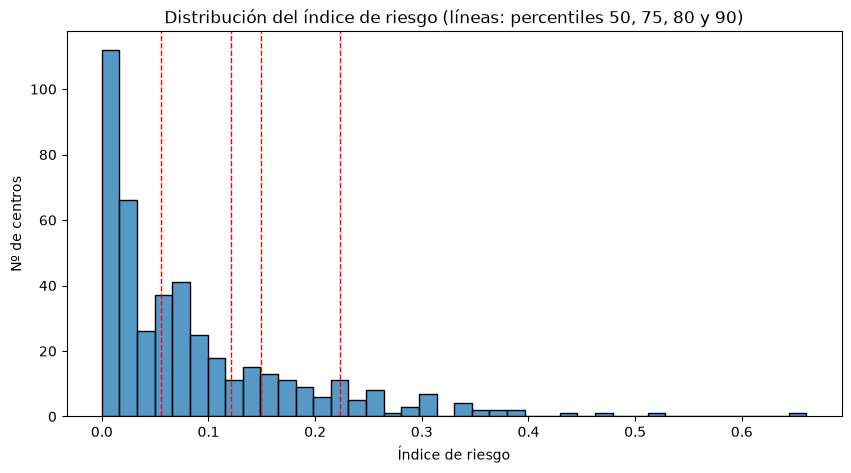

Percentil 50: 0.056
Percentil 75: 0.121
Percentil 80: 0.149
Percentil 90: 0.223


In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(indice["riesgo"], bins=40, ax=ax)
for percentil in [0.5, 0.75, 0.8, 0.9]:
    ax.axvline(indice["riesgo"].quantile(percentil), color="red", linestyle="--", linewidth=1)
ax.set_title("Distribución del índice de riesgo (líneas: percentiles 50, 75, 80 y 90)")
ax.set_xlabel("Índice de riesgo")
ax.set_ylabel("Nº de centros")
plt.show()

for percentil in [0.5, 0.75, 0.8, 0.9]:
    print(f"Percentil {int(percentil * 100)}: {indice['riesgo'].quantile(percentil):.3f}")

**Observación:** los umbrales son P50 = 0,056, P75 = 0,121, P80 = 0,149 y P90 = 0,223

**Decisión:** como el índice no tiene saltos naturales, los centros se clasifican por percentiles: prioridad alta el 20 % con más riesgo (a partir del percentil 80, donde termina el grupo principal del histograma), media del 50 % al 80 % y baja el 50 % restante. La lista de prioridad alta (unos 88 centros) es manejable, y el optimizador decidirá dentro de ella dónde actuar primero.

- clasificamos los centros por prioridad

In [25]:
corte_medio = indice["riesgo"].quantile(0.5)
corte_alto = indice["riesgo"].quantile(0.8)
indice["prioridad"] = pd.cut(
    indice["riesgo"],
    bins=[-np.inf, corte_medio, corte_alto, np.inf],
    labels=["baja", "media", "alta"]
)
indice["prioridad"].value_counts()

prioridad
baja     220
media    131
alta      88
Name: count, dtype: int64

**Observación:** 88 centros en prioridad alta (P80 o más), 131 en media y 220 en baja.

- los 10 centros con más riesgo y sus componentes

In [26]:
columnas_ver = ["nombre", "tipo_centro", "plazas", "lst_isocrona", "peligro", "exposicion", "vulnerabilidad", "capacidad", "riesgo"]
indice.nlargest(10, "riesgo")[columnas_ver].round(2)

,nombre,tipo_centro,plazas,lst_isocrona,peligro,exposicion,vulnerabilidad,capacidad,riesgo
47,"DOCTOR GONZALEZ BUENO, RESIDENCIA DE PERSONAS ...",residencia,601.0,47.18,0.99,1.00,0.71,0.05,0.66
45,"PLATA Y CASTAÑAR, RESIDENCIA DE PERSONAS MAYORES",residencia,220.0,46.83,0.98,0.91,0.78,0.24,0.53
176,CENTRO DE DIA PARA MAYORES SANIVIDA PUENTE DE ...,centro de día,180.0,45.48,0.90,0.99,0.67,0.22,0.47
50,"GRAN RESIDENCIA, RESIDENCIA DE PERSONAS MAYORES",residencia,368.0,45.43,0.89,0.97,0.93,0.46,0.43
436,RESIDENCIA DE PERSONAS MAYORES CASABLANCA VICÁ...,residencia,192.0,45.95,0.95,0.87,0.50,0.06,0.39
120,"BOUCO MADRID ARAVACA, RESIDENCIA DE PERSONAS M...",residencia,251.0,44.55,0.68,0.93,0.66,0.10,0.38
109,"SANIVIDA CIUDAD LINEAL, CENTRO DE DIA PARA MAY...",centro de día,135.0,44.92,0.79,0.95,0.78,0.35,0.38
237,"LUIS PEIDRO, CENTRO MUNICIPAL DE DIA",centro de día,150.0,44.86,0.78,0.97,0.86,0.43,0.37
212,"CARMEN CONDE, CENTRO MUNICIPAL DE DIA PARA ENF...",centro de día,80.0,45.32,0.87,0.78,0.87,0.40,0.36
395,RESIDENCIA DE PERSONAS MAYORES VALDELUZ LAS ME...,residencia,248.0,47.32,0.99,0.93,0.53,0.27,0.35


**Observación:** Doctor González Bueno sigue siendo el centro de mayor riesgo (0,66), por la combinación de mucho calor, muchas plazas y casi ninguna protección cerca (capacidad 0,05). Le siguen Plata y Castañar (0,53) y Sanivida Puente de Vallecas (0,47).

- prioridad por tipo de centro y por titularidad (descriptivo)

In [27]:
pd.crosstab(indice["tipo_centro"], indice["prioridad"], normalize="index").round(2)

prioridad,baja,media,alta
tipo_centro,,,
centro de día,0.45,0.34,0.21
centro de mayores,0.60,0.30,0.10
residencia,0.48,0.25,0.27
vivienda tutelada,0.62,0.25,0.12


**Observación:** las residencias tienen la mayor proporción en prioridad alta (27 %), seguidas de los centros de día (21 %). Los centros de mayores (10 %) y las viviendas tuteladas (12 %) tienen menos

In [28]:
pd.crosstab(indice["titularidad"], indice["prioridad"], normalize="index").round(2)

prioridad,baja,media,alta
titularidad,,,
PRIVADA CON ÁNIMO DE LUCRO,0.48,0.29,0.23
PRIVADA SIN ÁNIMO DE LUCRO,0.55,0.31,0.14
PÚBLICA,0.50,0.31,0.19


**Observación:** los centros privados con ánimo de lucro tienen la mayor proporción en prioridad alta (23 %), frente al 19 % de los públicos y el 14 % de los privados sin ánimo de lucro.

- mapa de los centros por prioridad

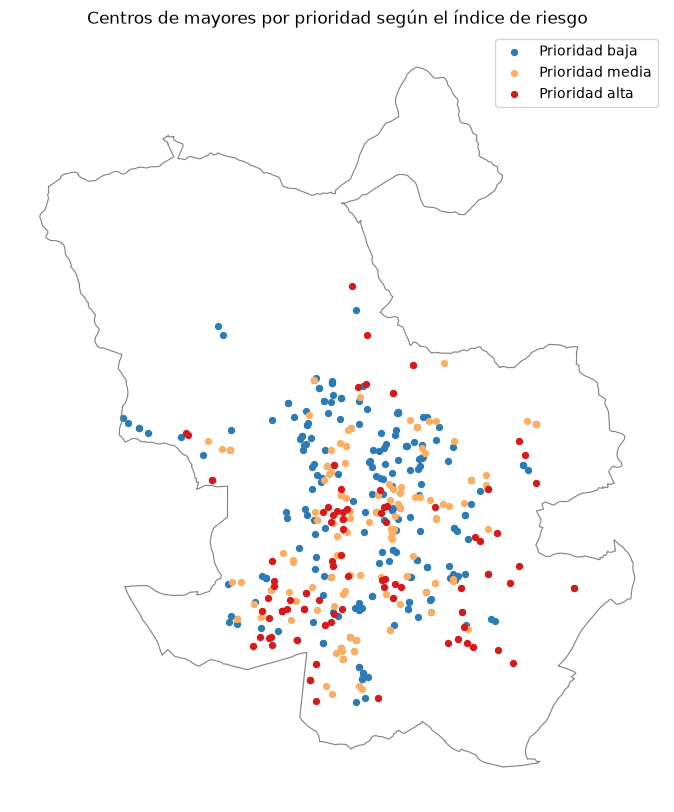

In [29]:
termino = gpd.read_file(RUTA_RAW + "limites/Termino_municipal/TERMINO_MUNICIPAL.shp")
colores = {"baja": "#2c7bb6", "media": "#fdae61", "alta": "#d7191c"}

fig, ax = plt.subplots(figsize=(10, 10))
termino.boundary.plot(ax=ax, color="grey", linewidth=0.8)
for nivel in ["baja", "media", "alta"]:
    indice[indice["prioridad"] == nivel].plot(ax=ax, color=colores[nivel], markersize=18, label=f"Prioridad {nivel}")
ax.set_title("Centros de mayores por prioridad según el índice de riesgo")
ax.legend()
ax.set_axis_off()
plt.show()

**Observación:** los centros de prioridad alta se concentran en el sur y el sureste (Latina, Carabanchel, Usera, Villaverde, Vallecas y Vicálvaro), con algunos en el centro y el este; en el norte predominan los de prioridad baja.

- guardamos el índice.

In [30]:
indice.to_file(RUTA_CLEAN + "indice_riesgo.gpkg", driver="GPKG")
print(indice.shape)

(439, 30)


**Decisión:** se guarda también el peso de cada centro (exposición × vulnerabilidad) como dato descriptivo. El optimizador de la priorización usa el riesgo completo, porque con solo el peso elegía zonas con muchos centros juntos aunque no fueran calientes ni estuvieran mal protegidas.

**Un hallazgo que conecta todo el proyecto:** varios de los 10 centros con más riesgo (Doctor González Bueno, Plata y Castañar, Casablanca Vicálvaro) también estaban entre los que más bajarían su temperatura con más arbolado en el simulador. Los centros que más lo necesitan son también donde intervenir rinde más, y eso es justo lo que el optimizador aprovechará.

- guardamos las capas de servicios para los mapas de la priorización y la app

In [31]:
fuentes.to_file(RUTA_CLEAN + "servicios_fuentes.gpkg", driver="GPKG")
salud.to_file(RUTA_CLEAN + "servicios_salud.gpkg", driver="GPKG")
refugios.to_file(RUTA_CLEAN + "servicios_refugios.gpkg", driver="GPKG")
print(len(fuentes), len(salud), len(refugios))

2186 183 156


- comprobamos que el script scrips/indice_riesgo.py da exactamente el mismo resultado que el notebook

In [32]:
from indice_riesgo import calcular_indice

indice_script, fuentes_script, salud_script, refugios_script = calcular_indice()
print("Índice:", indice.equals(indice_script))
print("Fuentes:", fuentes.equals(fuentes_script))
print("Salud:", salud.equals(salud_script))
print("Refugios:", refugios.equals(refugios_script))

Índice: True
Fuentes: True
Salud: True
Refugios: True
